# Experiment 6: A simple neural network
Aniruddh Vijayvargia (500125613), Batch D. Lab Manual, Chapter 7.

A 2-4-1 sigmoid network trained on XOR by hand-written backpropagation in NumPy,
for four learning rates, plus a zero-initialisation check.

In [1]:
import json, os, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10})
R = {"versions": {"python": platform.python_version(), "numpy": np.__version__,
                  "matplotlib": matplotlib.__version__}}

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)          # XOR

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

HIDDEN, EPOCHS, SEED = 4, 20000, 1

In [2]:
def init(seed, hidden=HIDDEN, zero=False):
    rng = np.random.default_rng(seed)
    W1 = np.zeros((2, hidden)) if zero else rng.normal(0, 1, (2, hidden))
    W2 = np.zeros((hidden, 1)) if zero else rng.normal(0, 1, (hidden, 1))
    return W1, np.zeros((1, hidden)), W2, np.zeros((1, 1))

def forward(params, inp):
    W1, b1, W2, b2 = params
    h = sigmoid(inp @ W1 + b1)
    return h, sigmoid(h @ W2 + b2)

def train_xor(lr, epochs=EPOCHS, seed=SEED, zero=False):
    W1, b1, W2, b2 = init(seed, zero=zero)
    loss = np.empty(epochs)
    for e in range(epochs):
        h, o = forward((W1, b1, W2, b2), X)                 # forward
        loss[e] = np.mean((o - y) ** 2)
        d_o = (o - y) * o * (1 - o)                         # output delta (sigma' = o(1-o))
        dW2 = h.T @ d_o; db2 = d_o.sum(0, keepdims=True)
        d_h = (d_o @ W2.T) * h * (1 - h)                    # hidden delta, chain rule
        dW1 = X.T @ d_h; db1 = d_h.sum(0, keepdims=True)
        W2 -= lr * dW2; b2 -= lr * db2                      # gradient descent
        W1 -= lr * dW1; b1 -= lr * db1
    return (W1, b1, W2, b2), loss

def converged(params, loss):
    """Converged = final MSE below 1e-3 and every output on the correct side of 0.5."""
    _, o = forward(params, X)
    return bool(loss[-1] < 1e-3 and np.all((o > 0.5) == (y > 0.5)))

In [3]:
LRS = (0.05, 0.5, 2.0, 10.0)
runs, rows = {}, []
for lr in LRS:
    params, loss = train_xor(lr)
    runs[lr] = (params, loss)
    plateau_end = int(np.argmax(loss < 0.5 * loss[0]))        # first epoch below half the initial loss
    rows.append({"lr": lr, "initial_mse": float(loss[0]), "final_mse": float(loss[-1]),
                 "epoch_half_loss": plateau_end, "converged": converged(params, loss),
                 "predictions": forward(params, X)[1].ravel().round(3).tolist()})
    print(rows[-1])
R["setup"] = {"shape": "2-4-1", "activation": "sigmoid (hidden and output)", "loss": "mean squared error",
              "seed": SEED, "epochs": EPOCHS, "init": "N(0,1) weights, zero biases"}
R["lr"] = rows

zp, zl = train_xor(0.5, zero=True)
R["zero_init"] = {"final_mse": float(zl[-1]), "hidden_units_identical": bool(np.allclose(zp[0][:, :1], zp[0])),
                  "predictions": forward(zp, X)[1].ravel().round(3).tolist()}
print("zero init:", R["zero_init"])

{'lr': 0.05, 'initial_mse': 0.2748629616482994, 'final_mse': 0.002314868988271694, 'epoch_half_loss': 6313, 'converged': False, 'predictions': [0.039, 0.953, 0.954, 0.058]}


{'lr': 0.5, 'initial_mse': 0.2748629616482994, 'final_mse': 0.00011144618732742166, 'epoch_half_loss': 633, 'converged': True, 'predictions': [0.008, 0.989, 0.991, 0.013]}


{'lr': 2.0, 'initial_mse': 0.2748629616482994, 'final_mse': 2.4552864803967287e-05, 'epoch_half_loss': 159, 'converged': True, 'predictions': [0.004, 0.995, 0.996, 0.006]}


{'lr': 10.0, 'initial_mse': 0.2748629616482994, 'final_mse': 5.807149088053469e-06, 'epoch_half_loss': 53, 'converged': True, 'predictions': [0.002, 0.998, 0.998, 0.003]}


zero init: {'final_mse': 0.25, 'hidden_units_identical': True, 'predictions': [0.5, 0.5, 0.5, 0.5]}


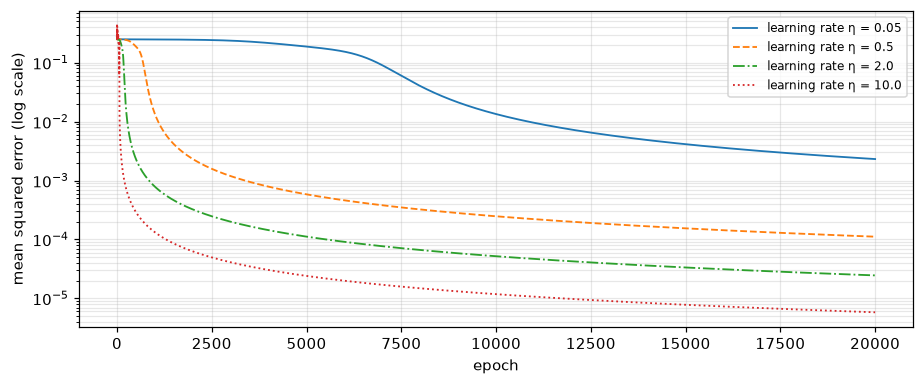

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for lr, ls in zip(LRS, ["-", "--", "-.", ":"]):
    ax.semilogy(runs[lr][1], ls, lw=1.2, label=f"learning rate η = {lr}")
ax.set_xlabel("epoch"); ax.set_ylabel("mean squared error (log scale)")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
fig.tight_layout(); fig.savefig("figs/fig6_1_loss.png")

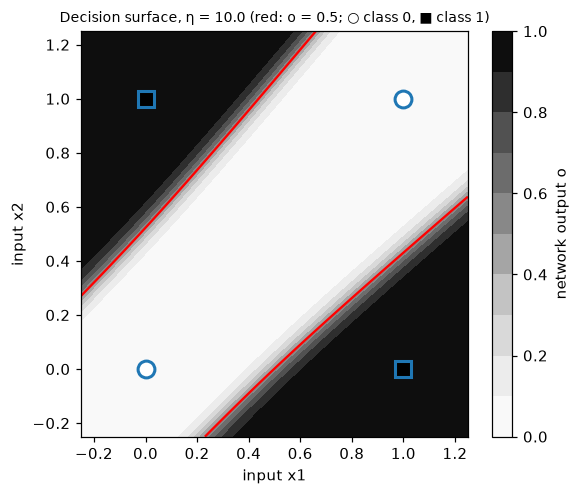

In [5]:
ok = [r for r in rows if r["converged"]]
best = min(ok, key=lambda r: r["final_mse"]) if ok else min(rows, key=lambda r: r["final_mse"])
R["best_lr"] = best["lr"]
params = runs[best["lr"]][0]
gx, gy = np.meshgrid(np.linspace(-0.25, 1.25, 300), np.linspace(-0.25, 1.25, 300))
Z = forward(params, np.c_[gx.ravel(), gy.ravel()])[1].reshape(gx.shape)
fig, ax = plt.subplots(figsize=(5.4, 4.6))
cf = ax.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11), cmap="Greys")
ax.contour(gx, gy, Z, levels=[0.5], colors="red", linewidths=1.5)
for (a, b), t in zip(X, y.ravel()):
    ax.plot(a, b, "o" if t == 0 else "s", ms=11, mfc="w" if t == 0 else "k", mec="tab:blue", mew=2)
fig.colorbar(cf, ax=ax, label="network output o")
ax.set_xlabel("input x1"); ax.set_ylabel("input x2")
ax.set_title(f"Decision surface, η = {best['lr']} (red: o = 0.5; ○ class 0, ■ class 1)", fontsize=9)
fig.tight_layout(); fig.savefig("figs/fig6_2_boundary.png")

In [6]:
with open("results.json", "w") as fh:
    json.dump(R, fh, indent=2)
print("saved results.json")

saved results.json
